Hệ số chặn (Intercept): [4.20634019]
Hệ số góc (Slope): [[2.9902591]]
Sai số bình phương trung bình (MSE): 0.9177532469714291
Hệ số xác định R^2 (R^2): 0.6521157503858556


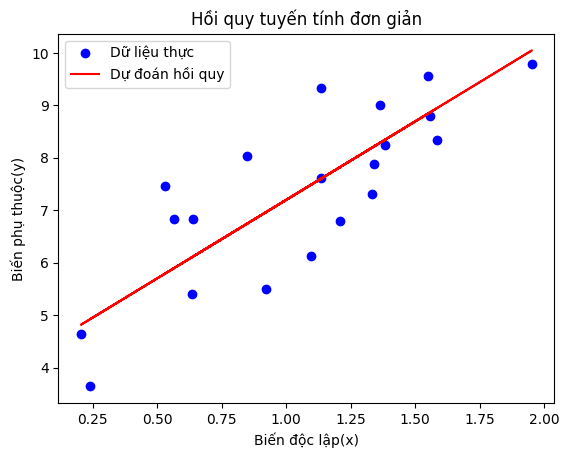

In [5]:
#Bài mẫu:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(0)
x = 2 * np.random.rand(100,1)
y = 4 + 3 * x + np.random.randn(100, 1)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số góc (Slope): {model.coef_}")
print(f"Sai số bình phương trung bình (MSE): {mse}")
print(f"Hệ số xác định R^2 (R^2): {r2}")

plt.scatter(x_test, y_test, color='blue', label="Dữ liệu thực")
plt.plot(x_test, y_pred, color='red', label="Dự đoán hồi quy")
plt.title("Hồi quy tuyến tính đơn giản")
plt.xlabel("Biến độc lập(x)")
plt.ylabel("Biến phụ thuộc(y)")
plt.legend()
plt.show()

Hệ số chặn: 110.9916971383721
Hệ số góc: [5.02034326]
MSE: 369.568132972255
R2: 0.9874623788373758
Giá nhà 85m2: 537.7208745102342 triệu đồng


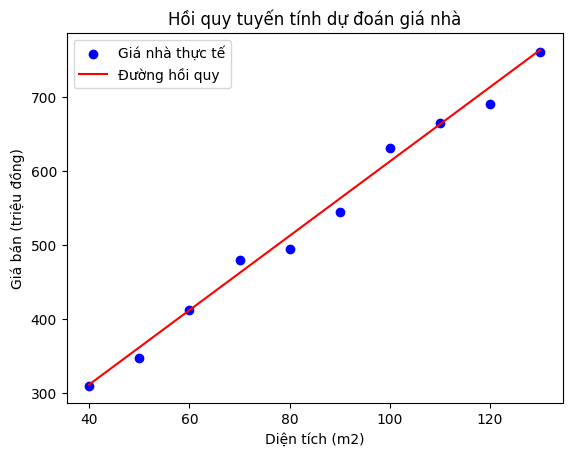

Độ nhiễu: 20
MSE: 433.84954501818856
R2: 0.9827306333588081


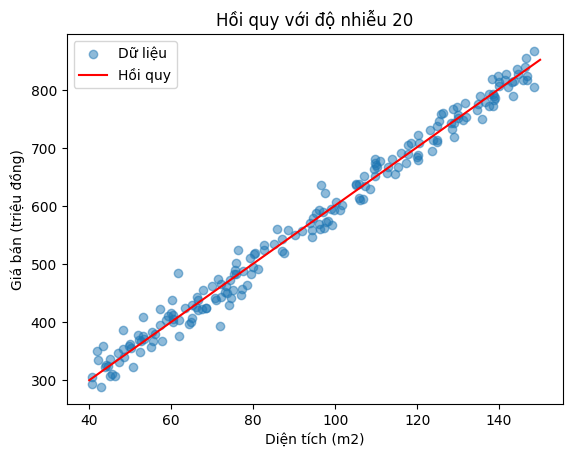

Độ nhiễu: 100
MSE: 11055.842758875002
R2: 0.6815884905467637


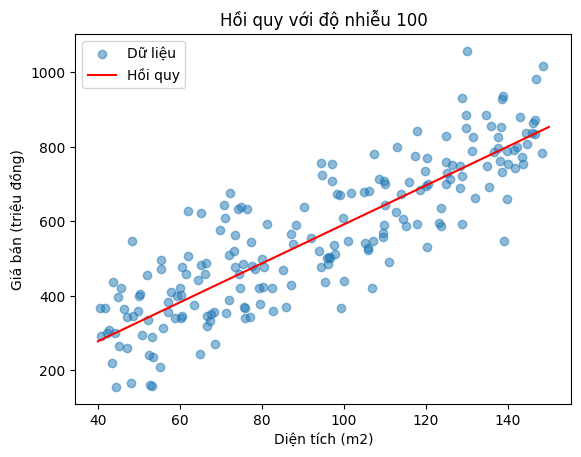

Hệ số chặn: 114.88051816034067
Các hệ số hồi quy: [ 4.89370099 42.212496   -3.47215549]
MSE: 1464.3280094918296
R2: 0.9429720761899312
Giá nhà dự đoán: 713.5273277879284 triệu đồng


In [6]:
#Bài 1:
#1.1:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Tạo dữ liệu diện tích và giá nhà
np.random.seed(42)
X = np.array([40, 50, 60, 70, 80, 90, 100, 110, 120, 130]).reshape(-1, 1)
y = 5 * X.ravel() + 100 + np.random.normal(0, 20, 10)

# Chia dữ liệu 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Huấn luyện mô hình
model = LinearRegression()
model.fit(X_train, y_train)

# Dự đoán
y_pred = model.predict(X_test)

print("Hệ số chặn:", model.intercept_)
print("Hệ số góc:", model.coef_)
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))

# Dự đoán giá nhà 85m2
print("Giá nhà 85m2:", model.predict([[85]])[0], "triệu đồng")

# Vẽ biểu đồ
X_line = np.linspace(40, 130, 100).reshape(-1, 1)
plt.scatter(X, y, color="blue", label="Giá nhà thực tế")
plt.plot(X_line, model.predict(X_line),
         color="red", label="Đường hồi quy")
plt.xlabel("Diện tích (m2)")
plt.ylabel("Giá bán (triệu đồng)")
plt.title("Hồi quy tuyến tính dự đoán giá nhà")
plt.legend()
plt.show()



#1.2:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

# Tăng lên 200 mẫu
X = np.random.uniform(40, 150, 200).reshape(-1, 1)

# Thử hai mức độ nhiễu
for noise in [20, 100]:
    y = 5 * X.ravel() + 100 + np.random.normal(0, noise, 200)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("Độ nhiễu:", noise)
    print("MSE:", mean_squared_error(y_test, y_pred))
    print("R2:", r2_score(y_test, y_pred))

    X_line = np.linspace(40, 150, 100).reshape(-1, 1)
    plt.scatter(X, y, alpha=0.5, label="Dữ liệu")
    plt.plot(X_line, model.predict(X_line),
             color="red", label="Hồi quy")
    plt.title(f"Hồi quy với độ nhiễu {noise}")
    plt.xlabel("Diện tích (m2)")
    plt.ylabel("Giá bán (triệu đồng)")
    plt.legend()
    plt.show()


#1.3:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

# Tạo dữ liệu 200 ngôi nhà
dien_tich = np.random.randint(40, 151, 200)
so_phong = np.random.randint(1, 6, 200)
tuoi_nha = np.random.randint(1, 31, 200)

X = np.column_stack((dien_tich, so_phong, tuoi_nha))

# Giá nhà phụ thuộc vào 3 yếu tố
y = (100 + 5 * dien_tich + 40 * so_phong
     - 3 * tuoi_nha + np.random.normal(0, 30, 200))

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Huấn luyện
model = LinearRegression()
model.fit(X_train, y_train)

# Dự đoán và đánh giá
y_pred = model.predict(X_test)

print("Hệ số chặn:", model.intercept_)
print("Các hệ số hồi quy:", model.coef_)
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))

# Dự đoán nhà 100m2, 3 phòng ngủ, 5 năm tuổi
nha_moi = np.array([[100, 3, 5]])
print("Giá nhà dự đoán:",
      model.predict(nha_moi)[0], "triệu đồng")


BMI | Xác suất | Dự đoán | Thực tế
27.34 | 0.53 | 1 | 1
19.59 | 0.06 | 0 | 0
30.19 | 0.77 | 1 | 0
20.94 | 0.10 | 0 | 1
15.17 | 0.01 | 0 | 0
36.79 | 0.97 | 1 | 1
39.67 | 0.99 | 1 | 1
31.94 | 0.86 | 1 | 1
31.13 | 0.82 | 1 | 1
31.56 | 0.85 | 1 | 0
18.52 | 0.04 | 0 | 0
38.12 | 0.98 | 1 | 1
35.88 | 0.97 | 1 | 1
23.96 | 0.25 | 0 | 0
35.43 | 0.96 | 1 | 1
24.67 | 0.30 | 0 | 0
17.21 | 0.03 | 0 | 0
18.62 | 0.04 | 0 | 0
23.27 | 0.20 | 0 | 0
16.86 | 0.02 | 0 | 0
20.70 | 0.09 | 0 | 1
22.61 | 0.16 | 0 | 0
16.29 | 0.02 | 0 | 0
29.03 | 0.68 | 1 | 1
28.57 | 0.64 | 1 | 0
24.72 | 0.30 | 0 | 0
22.77 | 0.17 | 0 | 0
35.05 | 0.95 | 1 | 1
25.68 | 0.38 | 0 | 1
18.00 | 0.03 | 0 | 0
32.70 | 0.89 | 1 | 1
25.80 | 0.39 | 0 | 1
38.05 | 0.98 | 1 | 1
33.23 | 0.91 | 1 | 1
37.71 | 0.98 | 1 | 1
37.69 | 0.98 | 1 | 1
23.08 | 0.19 | 0 | 0
32.58 | 0.89 | 1 | 1
17.26 | 0.03 | 0 | 0
34.28 | 0.94 | 1 | 1

Accuracy: 0.825
Ma trận nhầm lẫn:
[[16  3]
 [ 4 17]]
Báo cáo phân loại:
              precision    recall  f1-score   suppor

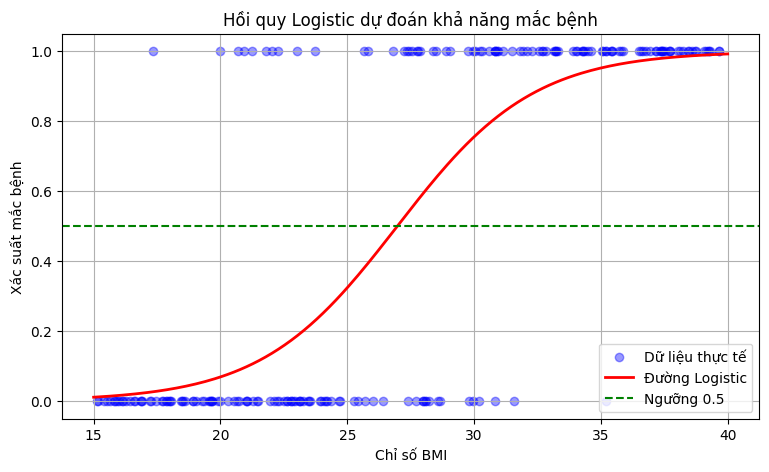

In [7]:
#Bài 2:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Tạo dữ liệu giả lập
np.random.seed(42)
BMI = np.random.uniform(15, 40, 200).reshape(-1, 1)

# BMI cao -> xác suất mắc bệnh giả lập cao hơn
prob = 1 / (1 + np.exp(-(BMI.ravel() - 27) / 3))
y = np.random.binomial(1, prob)

# 2. Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    BMI, y, test_size=0.2, random_state=42
)

# 3. Huấn luyện Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)

# 4. Dự đoán nhãn và xác suất
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("BMI | Xác suất | Dự đoán | Thực tế")
for i in range(len(X_test)):
    print(f"{X_test[i][0]:.2f} | {y_prob[i]:.2f} | {y_pred[i]} | {y_test[i]}")

# 5. Đánh giá mô hình
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Ma trận nhầm lẫn:")
print(confusion_matrix(y_test, y_pred))
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))

# 6. Trực quan hóa đường hồi quy Logistic
bmi_range = np.linspace(15, 40, 200).reshape(-1, 1)
prob_range = model.predict_proba(bmi_range)[:, 1]

plt.figure(figsize=(9, 5))
plt.scatter(BMI, y, color="blue", alpha=0.4,
            label="Dữ liệu thực tế")
plt.plot(bmi_range, prob_range, color="red",
         linewidth=2, label="Đường Logistic")
plt.axhline(0.5, color="green", linestyle="--",
            label="Ngưỡng 0.5")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.title("Hồi quy Logistic dự đoán khả năng mắc bệnh")
plt.legend()
plt.grid(True)
plt.show()


Số mẫu dữ liệu: 442
Số đặc trưng: 10
Tên đặc trưng: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Số giá trị thiếu: 0
MSE: 2900.193628493482
MAE: 42.79409467959994
R2 Score: 0.4526027629719195


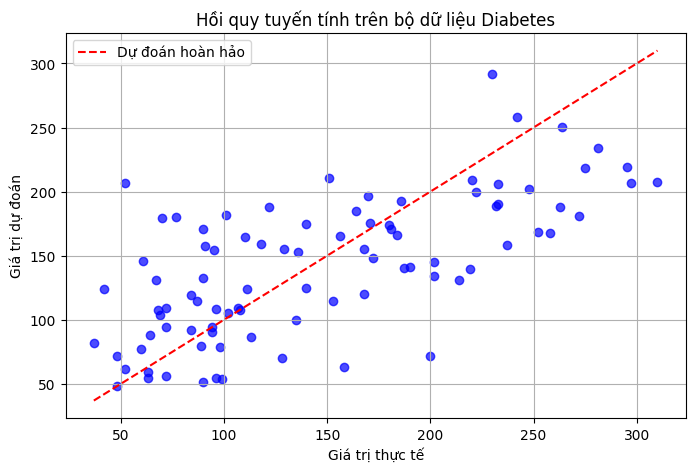

In [8]:
#Bài 3:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Tải dữ liệu
data = load_diabetes()
X = data.data
y = data.target

print("Số mẫu dữ liệu:", X.shape[0])
print("Số đặc trưng:", X.shape[1])
print("Tên đặc trưng:", data.feature_names)

# 2. Kiểm tra dữ liệu
print("Số giá trị thiếu:", np.isnan(X).sum())

# 3. Chia dữ liệu 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Xây dựng mô hình hồi quy
model = LinearRegression()

# 5. Huấn luyện
model.fit(X_train, y_train)

# 6. Dự đoán
y_pred = model.predict(X_test)

# 7. Đánh giá mô hình
print("MSE:", mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

# 8. So sánh giá trị thực tế và dự đoán
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color="blue", alpha=0.7)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val],
         color="red", linestyle="--", label="Dự đoán hoàn hảo")

plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")
plt.title("Hồi quy tuyến tính trên bộ dữ liệu Diabetes")
plt.legend()
plt.grid(True)
plt.show()